# Inference

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import cv2
import pandas as pd
import random
from sklearn.preprocessing import LabelEncoder
import os
import json
import matplotlib.pyplot as plt

def detect_food_in_image(image_path, model, label_encoder):
    # Load and preprocess the image
    image = cv2.imread(image_path)
    if image is None:
        return "Image not found."
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    original_image = image.copy()
    
    # For visualization
    plt.figure(figsize=(12, 12))
    plt.imshow(original_image)
    plt.title("Food Detection Results")
    
    results = []
    
    # # Method 1: Contour-based detection
    # # Convert to HSV color space for better color segmentation
    # hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    
    # # Apply Gaussian blur to reduce noise
    # blurred = cv2.GaussianBlur(hsv_image, (5, 5), 0)
    
    # # Use adaptive thresholding to find potential regions of interest
    # gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # thresh = cv2.adaptiveThreshold(
    #     gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    #     cv2.THRESH_BINARY_INV, 11, 2
    # )
    
    # # Find contours in the thresholded image
    # contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # # Filter contours by area to remove tiny regions
    # min_area = image.shape[0] * image.shape[1] * 0.01  # 1% of image area
    # significant_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]
    
    # # Analyze each significant contour
    # for i, contour in enumerate(significant_contours):
    #     # Get bounding rectangle
    #     x, y, w, h = cv2.boundingRect(contour)
        
    #     # Ensure the region is reasonably sized
    #     if w < 20 or h < 20:
    #         continue
            
    #     # Extract the region
    #     food_region = original_image[y:y+h, x:x+w]
        
    #     # Resize to standard size
    #     food_region_resized = cv2.resize(food_region, (IMG_SIZE, IMG_SIZE))
        
    #     # Normalize pixel values
    #     food_region_normalized = food_region_resized / 255.0
        
    #     # Predict
    #     prediction = model.predict(np.expand_dims(food_region_normalized, axis=0), verbose=0)
    #     predicted_class_idx = np.argmax(prediction)
    #     confidence = prediction[0][predicted_class_idx]
        
    #     # Filter predictions with low confidence
    #     if confidence < 0.4:
    #         continue
            
    #     # Convert to category name
    #     predicted_class = label_encoder.inverse_transform([predicted_class_idx])[0]
    #     category_name = next((cat['name'] for cat in coco_data['categories'] if cat['id'] == predicted_class), "Unknown")
        
    #     # Add to results
    #     results.append({
    #         'class_idx': predicted_class_idx,
    #         'category': category_name,
    #         'confidence': float(confidence),
    #         'bbox': [x, y, w, h]
    #     })
        
    #     # Draw rectangle and label on the image
    #     rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor='r', facecolor='none')
    #     plt.gca().add_patch(rect)
    #     plt.text(x, y - 5, f"{category_name} ({confidence:.2f})", 
    #              color='white', fontsize=12, backgroundcolor='red')
    
    # Method 2: Multi-scale sliding window detection
    # Run regardless of whether contours found anything, to improve detection of multiple foods
    print("Running sliding window detection for multiple food items...")
    
    # Define window sizes (relative to image size)
    window_sizes = [
        (image.shape[1]//2, image.shape[0]//2),  # Half image size
        # (image.shape[1]//3, image.shape[0]//3),  # One-third size
        # (image.shape[1]//4, image.shape[0]//4)   # One-fourth size
    ]
    
    # Smaller step size to catch more food items (with overlap)
    step_size = min(image.shape[0], image.shape[1]) // 12
    
    # Track detection regions to avoid duplicates
    detection_heatmap = np.zeros((image.shape[0], image.shape[1]), dtype=np.float32)
    sliding_window_results = []
    
    # Process each window size
    for win_w, win_h in window_sizes:
        # Skip if window is too small
        if win_w < 50 or win_h < 50:
            continue
            
        for y in range(0, image.shape[0] - win_h, step_size):
            for x in range(0, image.shape[1] - win_w, step_size):
                # Extract window
                window = original_image[y:y+win_h, x:x+win_w]
                
                # Resize to standard size
                window_resized = cv2.resize(window, (IMG_SIZE, IMG_SIZE))
                
                # Normalize pixel values
                window_normalized = window_resized / 255.0
                
                # Predict
                prediction = model.predict(np.expand_dims(window_normalized, axis=0), verbose=0)
                predicted_class_idx = np.argmax(prediction)
                confidence = prediction[0][predicted_class_idx]
                
                # Filter predictions with low confidence
                if confidence < 0.5:
                    continue
                    
                # Convert to category name
                predicted_class = label_encoder.inverse_transform([predicted_class_idx])[0]
                category_name = next((cat['name'] for cat in coco_data['categories'] if cat['id'] == predicted_class), "Unknown")
                
                # Add to sliding window results
                sliding_window_results.append({
                    'class_idx': predicted_class_idx,
                    'category': category_name,
                    'confidence': float(confidence),
                    'bbox': [x, y, win_w, win_h]
                })
                
                # Add to heatmap for later NMS
                detection_heatmap[y:y+win_h, x:x+win_w] += confidence
    
    # Non-maximum suppression to eliminate overlapping windows
    # Sort sliding window results by confidence (highest first)
    sliding_window_results.sort(key=lambda x: x['confidence'], reverse=True)
    
    # Keep track of which results to keep
    keep_results = []
    
    # Simple NMS implementation
    for i, current in enumerate(sliding_window_results):
        # Skip if this window was already suppressed
        if current in keep_results:
            continue
            
        # Current window coordinates
        x1, y1, w1, h1 = current['bbox']
        x2, y2 = x1 + w1, y1 + h1
        
        # Keep this window
        keep_results.append(current)
        
        # Check against all other windows
        for j, other in enumerate(sliding_window_results):
            if i == j or other in keep_results:
                continue
                
            # Other window coordinates
            x3, y3, w2, h2 = other['bbox']
            x4, y4 = x3 + w2, y3 + h2
            
            # Calculate intersection area
            x_overlap = max(0, min(x2, x4) - max(x1, x3))
            y_overlap = max(0, min(y2, y4) - max(y1, y3))
            intersection = x_overlap * y_overlap
            
            # Calculate union area
            area1 = w1 * h1
            area2 = w2 * h2
            union = area1 + area2 - intersection
            
            # Calculate IoU (Intersection over Union)
            iou = intersection / union if union > 0 else 0
            
            # If there's significant overlap and same category, suppress the lower confidence window
            if iou > 0.5 and current['category'] == other['category']:
                # Don't add other to keep_results - it's being suppressed
                pass
    
    # Add the filtered sliding window results to the overall results
    for result in keep_results:
        x, y, w, h = result['bbox']
        category_name = result['category']
        confidence = result['confidence']
        
        # Add to results if not already detected by contour method
        # (Simple check - if there's no major overlap with existing results)
        should_add = True
        for existing in results:
            ex, ey, ew, eh = existing['bbox']
            if (x < ex + ew and x + w > ex and 
                y < ey + eh and y + h > ey and
                existing['category'] == category_name):
                should_add = False
                break
                
        if should_add:
            results.append(result)
            
            # Draw rectangle and label on the image
            rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor='b', facecolor='none')
            plt.gca().add_patch(rect)
            plt.text(x, y - 5, f"{category_name} ({confidence:.2f})", 
                     color='white', fontsize=12, backgroundcolor='blue')
    
    # Display results
    plt.axis('off')
    plt.show()
    
    print(f"Detected {len(results)} food items in total.")
    return results



2025-05-25 12:15:56.647848: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748175356.669359  260111 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748175356.676260  260111 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1748175356.692172  260111 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748175356.692192  260111 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748175356.692194  260111 computation_placer.cc:177] computation placer alr

/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 16 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Created mapping for 905 image IDs to filenames
Testing food detection on image: dish_195_IMG_1818_jpeg.rf.1afc6da8d0cceb5ac10fcb61ad7b74b0.jpg
Running sliding window detection for multiple food items...


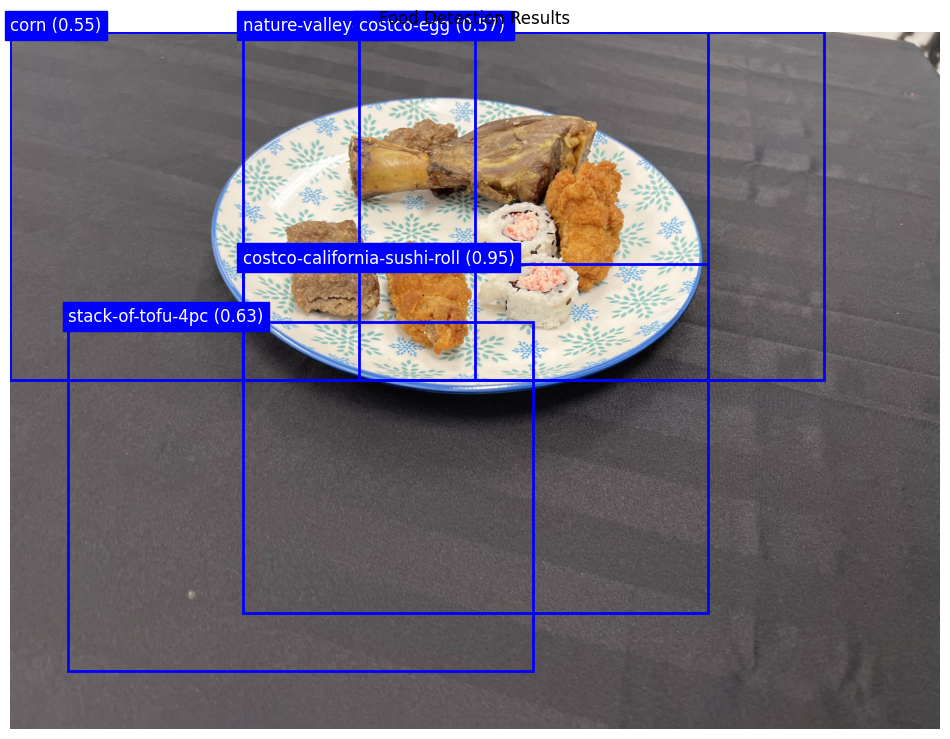

Detected 5 food items in total.
Detected food items:
1. costco-california-sushi-roll id: 10 - (Confidence: 0.95)
2. nature-valley-granola-bar id: 29 - (Confidence: 0.83)
3. stack-of-tofu-4pc id: 39 - (Confidence: 0.63)
4. costco-egg id: 12 - (Confidence: 0.57)
5. corn id: 9 - (Confidence: 0.55)


In [12]:
# Define constants
IMG_SIZE = 256  # Input size for MobileNetV2

# Load the saved model
model_path = "256_15_Epoch_raw_cnn.keras"
food_detection_model = tf.keras.models.load_model(model_path)

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")


category = coco_data['categories']
# Extract only the 'id' values from the categories
category_ids = [cat['id'] for cat in category]

# Initialize and fit the LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(category_ids)


# Test the detection on a sample image
sample_image_id = random.choice(list(image_id_to_filename.keys()))
sample_filename = image_id_to_filename[sample_image_id]
sample_image_path = os.path.join(images_path, sample_filename)

print(f"Testing food detection on image: {sample_filename}")

# Predict food categories
detected_foods = detect_food_in_image(sample_image_path, food_detection_model, label_encoder)

print("Detected food items:")
for i, food in enumerate(detected_foods):
    print(f"{i+1}. {food['category']} id: {food['class_idx']} - (Confidence: {food['confidence']:.2f})")

